In the mid-1980s a group at Morgan Stanley led by Nunzio Tartaglia noticed that shares of closely related companies, such as Coca-Cola and PepsiCo, tend to move together, and that when one runs ahead of the other the gap usually closes. Buying the laggard and selling the leader, again and again, made money for years. This **pairs trading**, the first “statistical arbitrage”, launched quantitative trading as an industry.

The idea is simple; doing it honestly is not. Two prices that wander together by coincidence look exactly like two prices that are tied together, and the tests that tell them apart are easy to misuse. This project builds those tests from scratch and then asks the question that matters: *do pairs found in the past keep their relationship in the future?*

:::eli5
Two dogs on one leash can run around the park in any direction, but they can never get far apart: when one pulls ahead, the leash drags it back. Two dogs without a leash may also run side by side for a while, by chance, but there is no reason for them to stay together. Pairs trading bets on the leash. The hard part is telling a leash from a coincidence.
:::

## Look at the big picture

**The problem.** From a universe of related US stocks and ETFs, select pairs whose prices are tied together, trade the gap between them when it is unusually wide, and decide whether the profits survive outside the period in which the pairs were chosen. **The data:** daily adjusted prices since 2006, split into a formation period (2010–2017) used for every choice and a trading period (2018–2026) used only once. **Measures:** cointegration p-values in both periods, the out-of-sample Sharpe ratio after costs, the share of pairs that are profitable, and the correlation with the market (a relative-value strategy should be close to market-neutral).

**Assumptions to check.** That the pairs found are not coincidences (multiple testing), that relationships persist (they may not), and that a hedge ratio fixed in the past stays valid (the Kalman filter tests that).

## Setup and data

Daily adjusted prices since 2006 of 23 US stocks and ETFs chosen in related groups: soft drinks, oil majors, banks, home improvement, card networks, parcel delivery, restaurants, two commodity-exporting country ETFs (Australia and Canada), gold and gold miners, and two equity indices.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
from itertools import combinations
from scipy import stats
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.adfvalues import mackinnonp
import json, warnings
warnings.filterwarnings("ignore")

mpl.rc("axes", labelsize=12, titlesize=13); mpl.rc("figure", dpi=110)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}
rng = np.random.default_rng(7)

px = pd.read_csv(DATA / "pairs_universe.csv", index_col="date", parse_dates=True)
lp = np.log(px)
rets = px.pct_change(fill_method=None)
print(px.shape, px.index[0].date(), "→", px.index[-1].date())

(5240, 23) 2006-01-03 → 2026-10-30


:::trap
These are all companies that still exist today: a **survivorship-biased** universe. A real pairs desk must include pairs that broke because one company was acquired, went bankrupt or changed business (Lehman Brothers was a bank too). Results on survivors are optimistic.
:::

## The mathematics of mean reversion

### Stationary and non-stationary series

A **stationary** series has a fixed mean and variance and tends to return to its mean; a **random walk** does not: its variance grows without limit and it has no level to return to. Prices behave like random walks (Chapter 1), so they cannot be traded for mean reversion on their own. A *combination* of two prices may be stationary even though each price is not; that combination is the trade.

:::math
**AR(1):** $x_t = c + \phi\,x_{t-1} + \varepsilon_t$. If $|\phi| < 1$ the series is stationary with mean $\mu = c/(1 - \phi)$ and is pulled back towards it; if $\phi = 1$ it is a random walk (a **unit root**). The expected gap from the mean shrinks by a factor $\phi$ each day, so it halves after

$$\text{half-life} = -\frac{\ln 2}{\ln \phi}\ \text{days}.$$

The continuous-time version is the **Ornstein–Uhlenbeck (OU) process** $dx = \kappa(\mu - x)\,dt + \sigma\,dW$, with $\phi = e^{-\kappa\Delta t}$ and half-life $\ln 2 / \kappa$. Its long-run standard deviation is $\sigma / \sqrt{2\kappa}$.
:::

### The augmented Dickey–Fuller test, from scratch

:::math
To test for a unit root, subtract $x_{t-1}$ from both sides of the AR model: $\Delta x_t = \alpha + \gamma\,x_{t-1} + \sum_{i=1}^{p}\delta_i \Delta x_{t-i} + e_t$, with $\gamma = \phi - 1$. The null hypothesis is $\gamma = 0$ (random walk). The test statistic is the ordinary t-statistic of $\hat\gamma$, but under the null it does **not** follow a t-distribution: Dickey and Fuller (1979) showed it has its own, more negative distribution. With a constant, the 5% critical value is about −2.86 instead of −1.65. MacKinnon (1994) published response surfaces for its p-values. The lagged differences “augment” the test to absorb autocorrelation in $e_t$.
:::

In [2]:
def adf_test(x, lags=1):
    x = np.asarray(x, float)
    dx = np.diff(x)
    y = dx[lags:]
    cols = [np.ones_like(y), x[lags:-1]] + [dx[lags - i: -i] for i in range(1, lags + 1)]
    A = np.column_stack(cols)
    b, *_ = np.linalg.lstsq(A, y, rcond=None)
    resid = y - A @ b
    s2 = resid @ resid / (len(y) - A.shape[1])
    se = np.sqrt(s2 * np.linalg.inv(A.T @ A)[1, 1])
    t = b[1] / se
    return t, mackinnonp(t, regression="c", N=1), 1 + b[1]

x_ar = np.zeros(3000)
for t in range(1, 3000):
    x_ar[t] = 0.98 * x_ar[t - 1] + rng.normal()
for name, series in [("random walk", np.cumsum(rng.normal(size=3000))), ("AR(1), φ = 0.98", x_ar), ("SPY log price", lp["SPY"].dropna().to_numpy())]:
    t_, p_, phi = adf_test(series)
    t_sm, p_sm = adfuller(series, maxlag=1, autolag=None, regression="c")[:2]
    print(f"{name:16s} ADF t = {t_:6.2f}  p = {p_:.3f}  (statsmodels: t = {t_sm:6.2f}, p = {p_sm:.3f})  phi = {phi:.4f}")

random walk      ADF t =  -2.09  p = 0.249  (statsmodels: t =  -2.09, p = 0.249)  phi = 0.9972
AR(1), φ = 0.98  ADF t =  -5.27  p = 0.000  (statsmodels: t =  -5.27, p = 0.000)  phi = 0.9815
SPY log price    ADF t =   0.49  p = 0.985  (statsmodels: t =   0.49, p = 0.985)  phi = 1.0001


The from-scratch test agrees with `statsmodels.adfuller`: it rejects the unit root for the AR(1) series, and cannot reject it for the random walk or for SPY's log price.

### The spurious-regression trap

Regress one random walk on another, *independent* one, and ordinary statistics will often report a strong relationship. Granger and Newbold (1974) showed the t-statistics are meaningless, because the residuals are themselves a random walk.

In [3]:
hits_levels, hits_diffs = 0, 0
n_trials, n_obs = 1000, 1000
for _ in range(n_trials):
    a, b = np.cumsum(rng.normal(size=n_obs)), np.cumsum(rng.normal(size=n_obs))
    res = stats.linregress(b, a); hits_levels += abs(res.slope / res.stderr) > 1.96
    res_d = stats.linregress(np.diff(b), np.diff(a)); hits_diffs += abs(res_d.slope / res_d.stderr) > 1.96
print(f"independent random walks: 'significant' slope in {hits_levels / n_trials:.0%} of regressions on levels, "
      f"{hits_diffs / n_trials:.0%} on differences")
R["spur"] = f"{hits_levels / n_trials:.0%}"; R["spur_d"] = f"{hits_diffs / n_trials:.0%}"

independent random walks: 'significant' slope in 93% of regressions on levels, 4% on differences


Two independent random walks show a “significant” relationship in 93% of regressions on their levels, against the expected 5% (4% on differences). Correlation of price *levels* means nothing. The **Spurious regression** tab of the playground lets you generate as many as you like.

### Cointegration: the leash, tested properly

:::math
Two non-stationary series $a_t$ and $b_t$ are **cointegrated** if some combination $s_t = a_t - \beta b_t$ is stationary. The **Engle–Granger** test (1987) has two steps: estimate $\beta$ by regressing $a_t$ on $b_t$, then run an ADF test on the residuals $s_t$. Because $\beta$ was chosen to make the residuals as small as possible, the residuals look more stationary than they are, so the critical values are more negative still (about −3.34 at 5% for two series).
:::

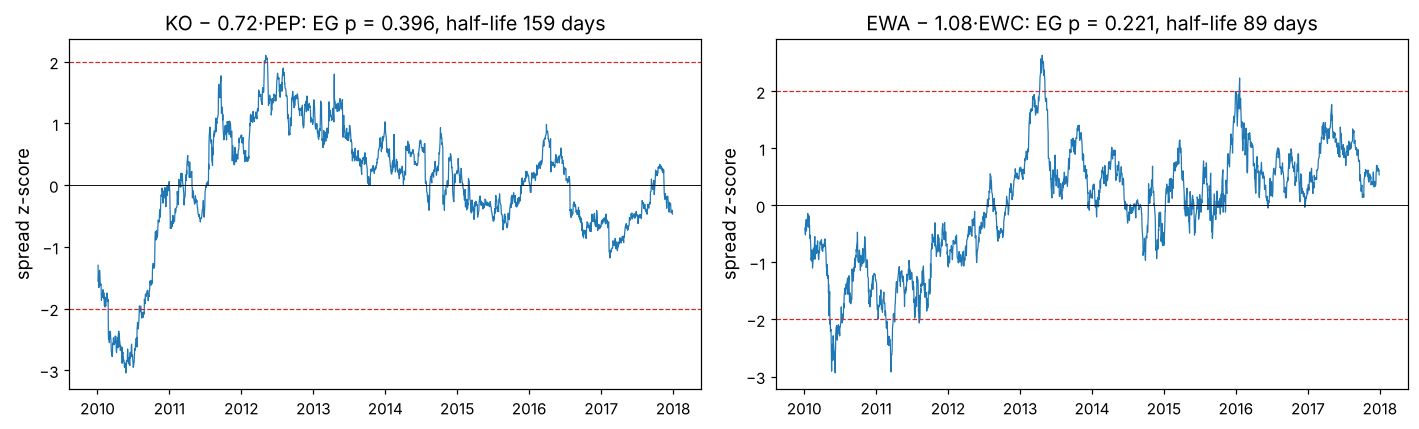

In [4]:
def engle_granger(a, b):
    beta, alpha = np.polyfit(b, a, 1)
    s = a - beta * b - alpha
    t_ = adf_test(s)[0]
    p = coint(a, b, trend="c", maxlag=1, autolag=None)[1]          # p-value with Engle-Granger critical values
    phi = np.polyfit(s[:-1], s[1:], 1)[0]
    return beta, s, t_, p, -np.log(2) / np.log(phi) if 0 < phi < 1 else np.inf

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, (A_, B_) in enumerate([("KO", "PEP"), ("EWA", "EWC")]):
    w = lp.loc["2010":"2017", [A_, B_]].dropna()
    beta, s, t_, p, hl = engle_granger(w[A_].to_numpy(), w[B_].to_numpy())
    ax[k].plot(w.index, (s - s.mean()) / s.std(), lw=0.8)
    ax[k].axhline(2, color="tab:red", ls="--", lw=0.8); ax[k].axhline(-2, color="tab:red", ls="--", lw=0.8); ax[k].axhline(0, color="k", lw=0.6)
    ax[k].set_title(f"{A_} − {beta:.2f}·{B_}: EG p = {p:.3f}, half-life {hl:.0f} days"); ax[k].set_ylabel("spread z-score")
save_fig("spreads"); plt.show()

![Figure 7-1. The two textbook pairs in 2010–2017, as z-scores of the log-price spread (dashed lines at ±2 standard deviations). Both fail the Engle–Granger test over this period.](images/spreads.png)

Surprise: the two most famous pairs in the textbooks are **not** cointegrated in 2010–2017. The Coca-Cola–PepsiCo spread spent two years above its mean (a half-life of about five months), and Australia–Canada drifted from below its mean to above it. They are related, they tend to move together, but over these eight years the leash was long and elastic, not tight. A famous story is not evidence.

## Finding pairs, and the multiple-testing problem

With 23 assets there are $\binom{23}{2} = 253$ possible pairs. Test them all on a **formation period** (2010–2017) and keep those with an Engle–Granger p-value below 5%. If no pair were truly cointegrated, we would still expect about $253 \times 0.05 \approx 13$ to pass by chance.

In [5]:
form, trade = slice("2010-01-01", "2017-12-31"), slice("2018-01-01", "2026-10-31")
rows = []
for a, b in combinations(px.columns, 2):
    w = lp.loc[form, [a, b]].dropna()
    if len(w) < 1500:
        continue
    beta, s, t_, p, hl = engle_granger(w[a].to_numpy(), w[b].to_numpy())
    rows.append({"pair": f"{a}/{b}", "a": a, "b": b, "beta": beta, "p_form": p, "half_life": hl, "corr_ret": rets.loc[form, a].corr(rets.loc[form, b])})
pairs = pd.DataFrame(rows).sort_values("p_form")
sel = pairs[(pairs["p_form"] < 0.05) & (pairs["half_life"].between(2, 120))].copy()
print(f"{len(pairs)} pairs tested; {int((pairs['p_form'] < 0.05).sum())} pass p < 0.05 (≈ {0.05 * len(pairs):.0f} expected by chance); "
      f"{len(sel)} also have a half-life between 2 and 120 days; Bonferroni (p < {0.05 / len(pairs):.4f}): {int((pairs['p_form'] < 0.05 / len(pairs)).sum())}")
print(sel[["pair", "beta", "p_form", "half_life", "corr_ret"]].round(3).to_string(index=False))
R["n_pass"] = int((pairs["p_form"] < 0.05).sum()); R["n_exp"] = f"{0.05 * len(pairs):.0f}"; R["n_sel"] = len(sel)
R["n_bonf"] = int((pairs["p_form"] < 0.05 / len(pairs)).sum())

253 pairs tested; 18 pass p < 0.05 (≈ 13 expected by chance); 18 also have a half-life between 2 and 120 days; Bonferroni (p < 0.0002): 0
   pair   beta  p_form  half_life  corr_ret
   HD/V  1.027   0.001     35.016     0.426
SPY/UPS  1.145   0.001     40.930     0.719
  UPS/V  0.430   0.007     52.506     0.432
CVX/EWA  1.405   0.009     48.450     0.621
 MA/UPS  2.172   0.011     52.691     0.470
QQQ/UPS  1.419   0.014     55.111     0.632
 KO/YUM  0.657   0.015     44.924     0.365
  BAC/C  1.372   0.020     73.543     0.828
 MA/YUM  1.801   0.020     60.074     0.422
PEP/UPS  1.012   0.023     58.021     0.459
UPS/WFC  0.753   0.027     62.262     0.556
LOW/WFC  1.541   0.027     47.051     0.480
  KO/MA  0.349   0.030     60.881     0.392
LOW/UPS  1.943   0.032     63.583     0.452
PEP/QQQ  0.709   0.033     56.643     0.500
PEP/SPY  0.887   0.033     56.808     0.579
GDX/WFC -1.200   0.047     47.687     0.077
LOW/PEP  1.881   0.048     57.150     0.327


18 pairs pass at the 5% level, against about 13 expected from pure chance, and only 0 survive a Bonferroni correction. In other words, most of the “cointegrated” pairs a naive screen finds are probably coincidences. Good practice: **start from economic reasons** (same industry, same customers, same commodity), test far fewer pairs, and demand stronger evidence.

### Does cointegration persist?

In [6]:
def eg_p(a, b, period):
    w = lp.loc[period, [a, b]].dropna()
    return engle_granger(w[a].to_numpy(), w[b].to_numpy())[3]
sel["p_trade"] = [eg_p(a, b, trade) for a, b in zip(sel["a"], sel["b"])]
print(sel[["pair", "p_form", "p_trade"]].round(3).to_string(index=False))
R["persist"] = f"{(sel['p_trade'] < 0.05).mean():.0%}"

   pair  p_form  p_trade
   HD/V   0.001    0.389
SPY/UPS   0.001    0.990
  UPS/V   0.007    0.748
CVX/EWA   0.009    0.543
 MA/UPS   0.011    0.737
QQQ/UPS   0.014    0.976
 KO/YUM   0.015    0.082
  BAC/C   0.020    0.571
 MA/YUM   0.020    0.046
PEP/UPS   0.023    0.417
UPS/WFC   0.027    0.645
LOW/WFC   0.027    0.416
  KO/MA   0.030    0.183
LOW/UPS   0.032    0.623
PEP/QQQ   0.033    0.642
PEP/SPY   0.033    0.712
GDX/WFC   0.047    0.568
LOW/PEP   0.048    0.089


Only 6% of the selected pairs are still cointegrated (p < 0.05) in 2018–2026. Relationships between prices change: business models diverge, one firm makes an acquisition, an industry gets disrupted. This is the central risk of statistical arbitrage.

## The trading rule

For each selected pair, the spread uses the hedge ratio $\beta$ estimated in the formation period, **frozen**, so nothing from the trading period leaks in. Each day we compute the z-score of the spread against its past 60 days and trade:

- enter **short the spread** (sell $a$, buy $\beta$ of $b$) when $z > 2$, **long** when $z < -2$;
- exit when $|z| < 0.5$; stop out when $|z| > 4$ (the relationship may be breaking) and stay out until $|z|$ is back below 2;
- dollar weights $(\mp 1, \pm\beta)$ scaled to a gross exposure of 1; pay 5 basis points per unit traded.

In [7]:
def trade_pair(a, b, beta, period, lookback=60, z_in=2.0, z_out=0.5, z_stop=4.0, cost_bps=5.0):
    w = lp.loc[:, [a, b]].dropna()
    s = w[a] - beta * w[b]
    z = ((s - s.rolling(lookback).mean()) / s.rolling(lookback).std()).loc[period]
    r = rets.loc[z.index, [a, b]].fillna(0)
    pos = np.zeros(len(z)); cur, blocked = 0, False
    zz = z.to_numpy()
    for t in range(len(zz)):
        if np.isnan(zz[t]):
            pos[t] = 0; continue
        if blocked and abs(zz[t]) < z_in:
            blocked = False
        if cur == 0 and not blocked:
            cur = -1 if zz[t] > z_in else (1 if zz[t] < -z_in else 0)
        elif cur != 0:
            if abs(zz[t]) < z_out:
                cur = 0
            elif abs(zz[t]) > z_stop:
                cur, blocked = 0, True
        pos[t] = cur
    pos = pd.Series(pos, index=z.index)
    held = pos.shift(1).fillna(0)                                        # decided at the close, held next day
    gross = 1 + abs(beta)
    pnl = held * (r[a] - beta * r[b]) / gross
    cost = pos.diff().abs().fillna(0) * cost_bps / 1e4 * 2              # both legs trade
    return pnl - cost, pos

def sharpe(x): return x.mean() / x.std() * np.sqrt(252) if x.std() > 0 else 0.0

ins, oos, n_trades = {}, {}, {}
for _, row in sel.iterrows():
    ins[row.pair], _ = trade_pair(row.a, row.b, row.beta, form)
    oos[row.pair], pos = trade_pair(row.a, row.b, row.beta, trade)
    n_trades[row.pair] = int((pos.diff().abs() > 0).sum() / 2)
ins, oos = pd.DataFrame(ins), pd.DataFrame(oos)
summary = pd.DataFrame({"Sharpe in sample (2010–17)": ins.apply(sharpe), "Sharpe out of sample (2018–26)": oos.apply(sharpe),
                        "round trips OOS": pd.Series(n_trades)}).round(2)
print(summary)
port_in, port_out = ins.mean(axis=1), oos.mean(axis=1)
print(f"equal-weight portfolio of pairs: Sharpe {sharpe(port_in):.2f} in sample → {sharpe(port_out):.2f} out of sample; "
      f"correlation with SPY OOS {port_out.corr(rets['SPY'].reindex(port_out.index)):+.2f}")
R["sh_in"] = f"{sharpe(port_in):.2f}"; R["sh_out"] = f"{sharpe(port_out):.2f}"
R["corr_out"] = f"{port_out.corr(rets['SPY'].reindex(port_out.index)):+.2f}"
R["share_pos_oos"] = f"{(summary['Sharpe out of sample (2018–26)'] > 0).mean():.0%}"

         Sharpe in sample (2010–17)  Sharpe out of sample (2018–26)  \
HD/V                           0.20                            0.49   
SPY/UPS                        0.19                           -0.02   
UPS/V                         -0.05                           -0.26   
CVX/EWA                        0.51                            0.16   
MA/UPS                         0.12                           -0.23   
QQQ/UPS                        0.29                           -0.14   
KO/YUM                        -0.22                            0.16   
BAC/C                          0.18                           -0.43   
MA/YUM                        -0.06                           -0.04   
PEP/UPS                        0.15                            0.03   
UPS/WFC                        0.17                           -0.25   
LOW/WFC                        0.10                            0.42   
KO/MA                          0.50                            0.30   
LOW/UP

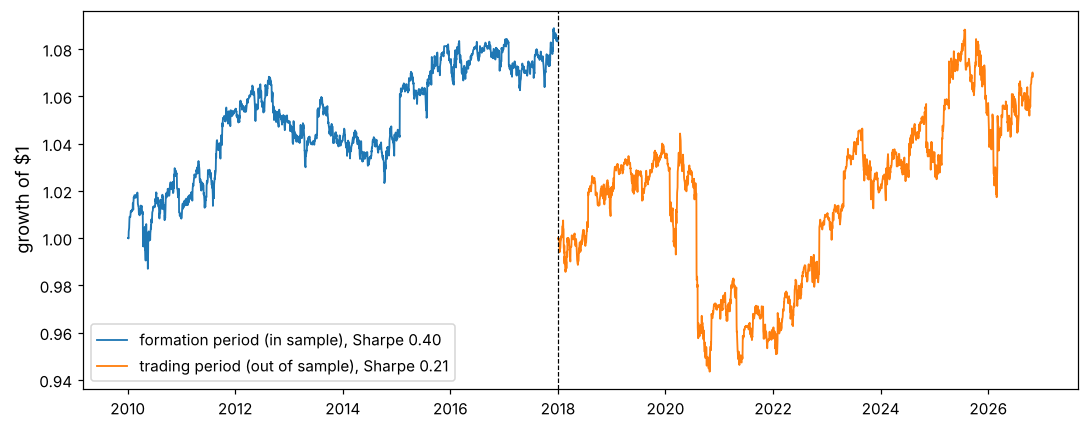

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot((1 + port_in).cumprod(), lw=1.2, label=f"formation period (in sample), Sharpe {sharpe(port_in):.2f}")
ax.plot((1 + port_out).cumprod(), lw=1.2, label=f"trading period (out of sample), Sharpe {sharpe(port_out):.2f}")
ax.axvline(pd.Timestamp("2018-01-01"), color="k", ls="--", lw=0.8); ax.legend(); ax.set_ylabel("growth of $1")
save_fig("pairs_in_out"); plt.show()

![Figure 7-2. An equal-weighted portfolio of the selected pairs, in the period used to select them and in the following years.](images/pairs_in_out.png)

The portfolio of pairs has a Sharpe ratio of 0.40 in the period used to find them and 0.21 afterwards; 61% of the pairs are profitable out of sample. Its correlation with SPY out of sample is +0.13: whatever it earns is close to market-neutral. Two lessons hide in these numbers. First, the gap between in-sample and out-of-sample is the cost of **selection**: we picked the pairs whose spreads happened to mean-revert best in the past. Second, even the in-sample Sharpe ratio is modest and the out-of-sample one is not zero, although only 6% of the pairs stay cointegrated. A 60-day z-score rule is really a bet on *short-term* reversal of the gap between two related assets, and that works a little even without a strict long-run leash. A little is not much: a Sharpe ratio of 0.21 with a drawdown of about 10% in 2020 (Figure 7-2) would not pay for a desk.

## A hedge ratio that adapts: the Kalman filter

A fixed $\beta$ assumes the relationship never changes. The **Kalman filter** treats the hedge ratio (and intercept) as hidden states that drift slowly, and updates them every day as new prices arrive.

:::math
State: $\theta_t = (\alpha_t, \beta_t)^\top$ with $\theta_t = \theta_{t-1} + \eta_t$, $\eta_t \sim \mathcal N(0, Q)$. Observation: $a_t = H_t\theta_t + \epsilon_t$ with $H_t = (1, b_t)$ and $\epsilon_t \sim \mathcal N(0, V)$. Each day:

1. **Predict:** $\hat\theta_{t|t-1} = \hat\theta_{t-1}$, $P_{t|t-1} = P_{t-1} + Q$.
2. **Forecast error:** $e_t = a_t - H_t\hat\theta_{t|t-1}$, with variance $F_t = H_t P_{t|t-1} H_t^\top + V$.
3. **Update:** Kalman gain $K_t = P_{t|t-1}H_t^\top / F_t$; $\hat\theta_t = \hat\theta_{t|t-1} + K_t e_t$; $P_t = (I - K_t H_t) P_{t|t-1}$.

The forecast error divided by its standard deviation, $e_t / \sqrt{F_t}$, is itself a z-score of the spread, available every day with no lookback window.
:::

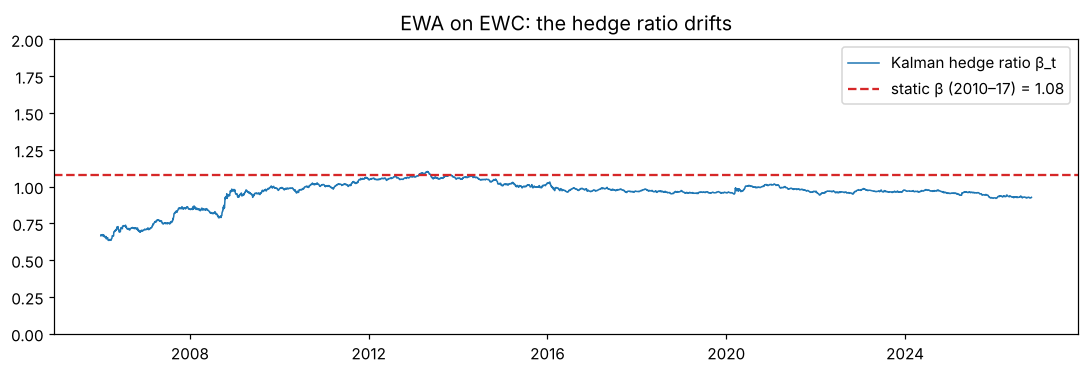

EWA/EWC out of sample 2018–2026: static-β z-score rule Sharpe 0.32, Kalman rule Sharpe 0.43


In [9]:
def kalman_pair(a, b, delta=1e-4, V=1e-3):
    n = len(a); theta = np.zeros(2); P = np.eye(2); Q = delta / (1 - delta) * np.eye(2)
    betas, z = np.zeros(n), np.zeros(n)
    for t in range(n):
        H = np.array([1.0, b[t]])
        P = P + Q                                                       # predict
        e = a[t] - H @ theta; F = H @ P @ H + V                          # forecast error
        K = P @ H / F                                                   # gain
        theta = theta + K * e; P = P - np.outer(K, H) @ P                # update
        betas[t], z[t] = theta[1], e / np.sqrt(F)
    return betas, z

w = lp[["EWA", "EWC"]].dropna()
betas, zk = kalman_pair(w["EWA"].to_numpy(), w["EWC"].to_numpy())
static_beta = np.polyfit(w.loc[form, "EWC"], w.loc[form, "EWA"], 1)[0]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(w.index, betas, lw=1, label="Kalman hedge ratio β_t"); ax.axhline(static_beta, color="tab:red", ls="--", label=f"static β (2010–17) = {static_beta:.2f}")
ax.set_ylim(0, 2); ax.legend(); ax.set_title("EWA on EWC: the hedge ratio drifts")
save_fig("kalman_beta"); plt.show()

def trade_signal(zser, r_a, r_b, beta_ser, z_in=1.0, z_out=0.0, cost_bps=5.0):
    pos = np.zeros(len(zser)); cur = 0
    for t, zt in enumerate(zser):
        if cur == 0:
            cur = -1 if zt > z_in else (1 if zt < -z_in else 0)
        elif (cur == -1 and zt < z_out) or (cur == 1 and zt > -z_out):
            cur = 0
        pos[t] = cur
    pos = pd.Series(pos, index=r_a.index); held = pos.shift(1).fillna(0); bh = beta_ser.shift(1).fillna(1.0)
    pnl = held * (r_a - bh * r_b) / (1 + bh.abs())
    return pnl - pos.diff().abs().fillna(0) * cost_bps / 1e4 * 2

r_ab = rets.loc[w.index, ["EWA", "EWC"]].fillna(0)
kal = trade_signal(pd.Series(zk, index=w.index), r_ab["EWA"], r_ab["EWC"], pd.Series(betas, index=w.index)).loc[trade]
stat, _ = trade_pair("EWA", "EWC", static_beta, trade)
print(f"EWA/EWC out of sample 2018–2026: static-β z-score rule Sharpe {sharpe(stat):.2f}, Kalman rule Sharpe {sharpe(kal):.2f}")
R["kal_sh"] = f"{sharpe(kal):.2f}"; R["stat_sh"] = f"{sharpe(stat):.2f}"
R["beta_min"] = f"{np.percentile(betas[500:], 5):.2f}"; R["beta_max"] = f"{np.percentile(betas[500:], 95):.2f}"

![Figure 7-3. The Kalman filter’s estimate of the EWA–EWC hedge ratio rose from about 0.65 in 2006 to about 1.1 in 2013 and then drifted back below 1; the static ratio from the formation period (dashed) sits above it for the whole trading period.](images/kalman_beta.png)

The Kalman hedge ratio for Australia against Canada ranged between 0.92 and 1.06 (5th to 95th percentile) over the sample. Out of sample, the static-β rule has a Sharpe ratio of 0.32 and the Kalman rule (entering at $|e_t/\sqrt{F_t}| > 1$ and exiting at 0) 0.43. That is one pair and one period, so the difference is well inside the noise of Chapter 1's luck lab; treat it as a sketch of the method, not a verdict. An adaptive hedge ratio does not make a dead relationship come back, but it keeps the spread closer to stationary when the relationship slowly drifts. The price is two tuning parameters ($\delta$ and $V$), which decide how fast $\beta$ may move: tune them only on the formation period.

## Present your solution

- **What worked.** The mathematics: from-scratch ADF and Engle–Granger tests that match `statsmodels`, half-lives, and a Kalman filter for drifting hedge ratios.
- **What the data say.** A screen of 253 pairs finds only a few more “cointegrated” pairs than chance predicts, and none survives a Bonferroni correction; most relationships found in 2010–2017 did not survive to 2018–2026, and the selected pairs' out-of-sample Sharpe ratio (0.21) is far below the in-sample one (0.40). Classic pairs trading of large stocks has decayed since the 1990s (Gatev, Goetzmann and Rouwenhorst, 2006, documented the decline), as many funds compete for the same gaps.
- **How professionals do it now.** Many assets at once (baskets and residuals of factor models, which is Chapter 6's cross-section combined with this chapter's mean reversion), short holding periods with careful cost control, and economic reasons for every relationship. The stop-loss and the decision to retire a pair are as important as the entry rule.

## Launch, monitor and maintain

- **Re-screen on a schedule** (for example every year, with the same rules and the same number of pairs tested), and retire pairs rather than keep them out of loyalty. Record why each pair was selected: an economic reason, not only a p-value.
- **Monitor each live pair**: the rolling half-life of its spread, the time spent beyond the stop level, and the Kalman hedge ratio. A half-life that keeps growing means the leash is breaking.
- **Corporate events break pairs overnight.** Mergers, spin-offs and index changes need a manual check before the next trade; most pairs desks flatten a pair on the announcement.
- **Costs and borrowing.** Every trade has a short leg. Check that the stock can be borrowed and include the borrow fee; for hard-to-borrow names it can exceed the whole edge.

## Try it out

::playground animations/pairs_lab.html 780

Simulate an Ornstein–Uhlenbeck spread with your own half-life, mix in a random walk to weaken the leash, trade it with your own entry, exit and cost settings, and watch how quickly costs eat a fast-reverting spread. The second tab generates spurious regressions between independent random walks.

## Exercises

:::exercise
1. Choose the entry threshold (1, 1.5, 2, 2.5) on the formation period only, then report the out-of-sample Sharpe ratio. Compare with the default of 2.
2. Re-estimate $\beta$ every year on a rolling three-year window instead of freezing it. Does that help the selected pairs?
3. Fit an OU process to the KO/PEP spread by maximum likelihood (its transition density is normal) and compare the half-life with the AR(1) estimate.
4. Build a three-asset **basket** of XOM, CVX and COP with the Johansen test (`statsmodels.tsa.vector_ar.vecm.coint_johansen`) and trade its first cointegrating vector.
5. Estimate how many of the 253 pairs would pass the 5% screen if all 23 price series were replaced by independent random walks of the same length. Compare with the real screen.
:::

<details><summary>Solutions</summary>

In [10]:
# 1
best = {}
for z_in in [1.0, 1.5, 2.0, 2.5]:
    best[z_in] = sharpe(pd.DataFrame({r_.pair: trade_pair(r_.a, r_.b, r_.beta, form, z_in=z_in)[0] for _, r_ in sel.iterrows()}).mean(axis=1))
z_star = max(best, key=best.get)
oos_star = pd.DataFrame({r_.pair: trade_pair(r_.a, r_.b, r_.beta, trade, z_in=z_star)[0] for _, r_ in sel.iterrows()}).mean(axis=1)
print("in-sample Sharpe by threshold:", {k: round(v, 2) for k, v in best.items()}, "→ chosen", z_star, "OOS Sharpe", round(sharpe(oos_star), 2))

# 5
n_fake = []
for rep in range(5):
    fake = pd.DataFrame(np.cumsum(rng.normal(0, 0.015, size=(2000, 23)), axis=0))
    n_fake.append(sum(coint(fake[i], fake[j], maxlag=1, autolag=None)[1] < 0.05 for i, j in combinations(range(23), 2)))
print("pairs passing with independent random walks:", n_fake, "mean", np.mean(n_fake))

in-sample Sharpe by threshold: {1.0: np.float64(0.16), 1.5: np.float64(0.35), 2.0: np.float64(0.4), 2.5: np.float64(0.36)} → chosen 2.0 OOS Sharpe 0.21


pairs passing with independent random walks: [11, 11, 5, 11, 5] mean 8.6


With pure random walks the screen passes between 5 and 11 of the 253 pairs (the count jumps around because the pairs share series, so their tests are not independent). The real screen's 18 is a little more than chance, so a few relationships may be real, but the p-values alone cannot tell you which.

</details>

## What's next

All strategies so far trade the assets themselves. Chapter 8 moves to **options**, whose prices depend on volatility rather than direction, builds the pricing machinery (trees, Monte Carlo, Black–Scholes, Heston), simulates delta hedging, and trains a neural network, written from scratch in NumPy, to price options about a hundred times faster than the model it learns from.